# Image Classification using CNN

## 1. Importing Libraries 

In [21]:
import tensorflow as tf 
from tensorflow.keras import layers, models, datasets 
import matplotlib.pyplot as plt 
import numpy as np

## 2. Downloading and Preparing the Dataset

In [22]:
(x_train, y_train), (x_test, y_test) = datasets.cifar10.load_data()

d:\Github\deep-learning-for-computer-vision\py-env\Lib\site-packages\keras\src\datasets\cifar.py:18: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  d = cPickle.load(f, encoding="bytes")


In [23]:
x_train 

array([[[[ 59,  62,  63],
         [ 43,  46,  45],
         [ 50,  48,  43],
         ...,
         [158, 132, 108],
         [152, 125, 102],
         [148, 124, 103]],

        [[ 16,  20,  20],
         [  0,   0,   0],
         [ 18,   8,   0],
         ...,
         [123,  88,  55],
         [119,  83,  50],
         [122,  87,  57]],

        [[ 25,  24,  21],
         [ 16,   7,   0],
         [ 49,  27,   8],
         ...,
         [118,  84,  50],
         [120,  84,  50],
         [109,  73,  42]],

        ...,

        [[208, 170,  96],
         [201, 153,  34],
         [198, 161,  26],
         ...,
         [160, 133,  70],
         [ 56,  31,   7],
         [ 53,  34,  20]],

        [[180, 139,  96],
         [173, 123,  42],
         [186, 144,  30],
         ...,
         [184, 148,  94],
         [ 97,  62,  34],
         [ 83,  53,  34]],

        [[177, 144, 116],
         [168, 129,  94],
         [179, 142,  87],
         ...,
         [216, 184, 140],
        

In [24]:
x_train.shape 

(50000, 32, 32, 3)

| Chiều | Giá trị | Ý nghĩa |
|---|---|---|
| 50000 | 50,000 | Số lượng ảnh |
| 32 | 32 | Chiều cao ảnh (32 pixels) |
| 32 | 32 | Chiều rộng ảnh (32 pixels) |
| 3 | 3 | Số kênh màu (R, G, B) |

In [25]:
x_test.shape

(10000, 32, 32, 3)

In [26]:
y_train

array([[6],
       [9],
       [9],
       ...,
       [9],
       [1],
       [1]], shape=(50000, 1), dtype=uint8)

| Số | Loại |
|---|---|
| 0 | airplane |
| 1 | automobile |
| 2 | bird |
| 3 | cat |
| 4 | deer |
| 5 | dog |
| 6 | frog |
| 7 | horse |
| 8 | ship |
| 9 | truck |

### normalize 

In [27]:
x_train, x_test = x_train / 255.0, x_test / 255.0

In [28]:
x_train 

array([[[[0.23137255, 0.24313725, 0.24705882],
         [0.16862745, 0.18039216, 0.17647059],
         [0.19607843, 0.18823529, 0.16862745],
         ...,
         [0.61960784, 0.51764706, 0.42352941],
         [0.59607843, 0.49019608, 0.4       ],
         [0.58039216, 0.48627451, 0.40392157]],

        [[0.0627451 , 0.07843137, 0.07843137],
         [0.        , 0.        , 0.        ],
         [0.07058824, 0.03137255, 0.        ],
         ...,
         [0.48235294, 0.34509804, 0.21568627],
         [0.46666667, 0.3254902 , 0.19607843],
         [0.47843137, 0.34117647, 0.22352941]],

        [[0.09803922, 0.09411765, 0.08235294],
         [0.0627451 , 0.02745098, 0.        ],
         [0.19215686, 0.10588235, 0.03137255],
         ...,
         [0.4627451 , 0.32941176, 0.19607843],
         [0.47058824, 0.32941176, 0.19607843],
         [0.42745098, 0.28627451, 0.16470588]],

        ...,

        [[0.81568627, 0.66666667, 0.37647059],
         [0.78823529, 0.6       , 0.13333333]

In [29]:
x_test 

array([[[[0.61960784, 0.43921569, 0.19215686],
         [0.62352941, 0.43529412, 0.18431373],
         [0.64705882, 0.45490196, 0.2       ],
         ...,
         [0.5372549 , 0.37254902, 0.14117647],
         [0.49411765, 0.35686275, 0.14117647],
         [0.45490196, 0.33333333, 0.12941176]],

        [[0.59607843, 0.43921569, 0.2       ],
         [0.59215686, 0.43137255, 0.15686275],
         [0.62352941, 0.44705882, 0.17647059],
         ...,
         [0.53333333, 0.37254902, 0.12156863],
         [0.49019608, 0.35686275, 0.1254902 ],
         [0.46666667, 0.34509804, 0.13333333]],

        [[0.59215686, 0.43137255, 0.18431373],
         [0.59215686, 0.42745098, 0.12941176],
         [0.61960784, 0.43529412, 0.14117647],
         ...,
         [0.54509804, 0.38431373, 0.13333333],
         [0.50980392, 0.37254902, 0.13333333],
         [0.47058824, 0.34901961, 0.12941176]],

        ...,

        [[0.26666667, 0.48627451, 0.69411765],
         [0.16470588, 0.39215686, 0.58039216]

In [30]:
num_classes = 10
# One-hot encoding 
# để cho các giá trị phân loại bình đẳng với nhau 
y_train = tf.keras.utils.to_categorical(y_train, num_classes)
y_test  = tf.keras.utils.to_categorical(y_test , num_classes)

In [31]:
y_train

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.],
       ...,
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.]], shape=(50000, 10))

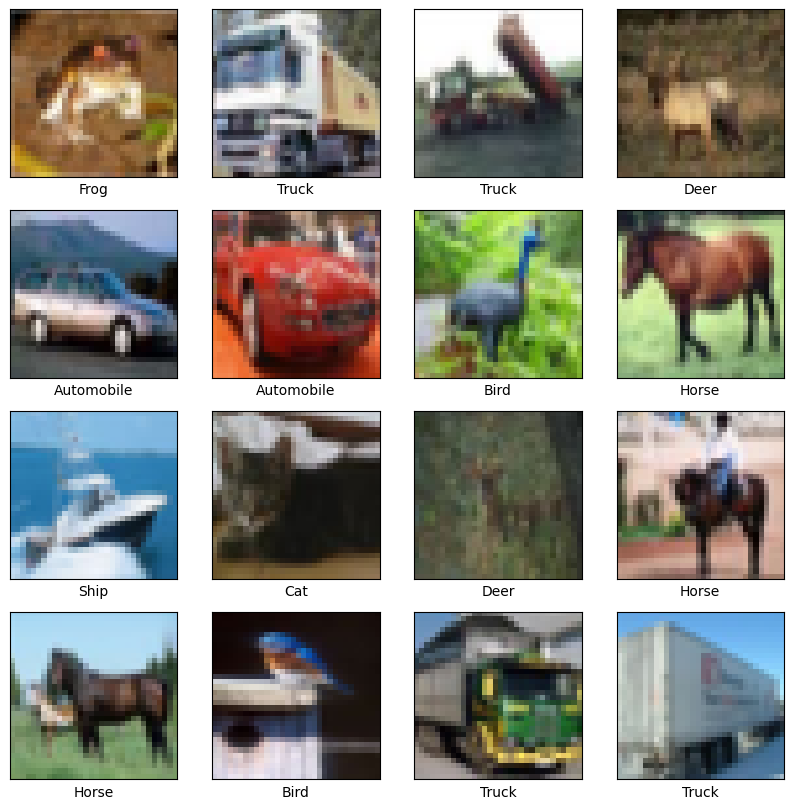

In [32]:
class_names = ['Airplane','Automobile','Bird','Cat','Deer','Dog','Frog','Horse','Ship','Truck']

plt.figure(figsize=(10,10))
for i in range(16):
    plt.subplot(4,4,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[i])
    plt.xlabel(class_names[np.argmax(y_train[i])])
plt.show()

## 3. Building the CNN Model 

In [33]:
model1 = models.Sequential([
    
    layers.Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(32,32,3)),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.Flatten(),

    layers.Dense(64, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

model1.summary()

d:\Github\deep-learning-for-computer-vision\py-env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 319,178 (1.22 MB)

 Trainable params: 319,178 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

### Giải thích từng layer

| Layer | Tham số | Output Shape | Ý nghĩa |
|---|---|---|---|
| Conv2D | 32 filters, (3×3), relu, padding='same' | (32, 32, 32) | Phát hiện các đặc trưng cơ bản: cạnh, góc, màu sắc |
| MaxPooling2D | (2×2) | (16, 16, 32) | Giảm kích thước xuống 1/2, giữ thông tin quan trọng |
| Conv2D | 64 filters, (3×3), relu, padding='same' | (16, 16, 64) | Học các đặc trưng phức tạp hơn |
| MaxPooling2D | (2×2) | (8, 8, 64) | Giảm kích thước xuống 1/2 lần nữa |
| Conv2D | 64 filters, (3×3), relu, padding='same' | (8, 8, 64) | Học các đặc trưng sâu hơn |
| Flatten | — | (4096,) | Chuyển ma trận 3D → vector 1D |
| Dense | 64 neurons, relu | (64,) | Fully connected, học cách phân loại |
| Dense | 10 neurons, softmax | (10,) | Output 10 xác suất tương ứng 10 class |

### Luồng xử lý dữ liệu

```
Input      (32, 32, 3)   ← ảnh màu 32×32
Conv2D  →  (32, 32, 32)
MaxPool →  (16, 16, 32)
Conv2D  →  (16, 16, 64)
MaxPool →  (8,  8,  64)
Conv2D  →  (8,  8,  64)
Flatten →  (4096,)
Dense   →  (64,)
Output  →  (10,)         ← 10 xác suất, tổng = 1.0
```

### Lưu ý
- **relu**: triệt tiêu giá trị âm, giúp model học nhanh hơn
- **padding='same'**: giữ nguyên kích thước sau Conv2D
- **softmax**: chuyển output thành xác suất, class có xác suất cao nhất là kết quả dự đoán

In [34]:
model1.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

history = model1.fit(x_train, y_train,
                    epochs=15,
                    batch_size=64,
                    validation_split=0.2,
                    verbose=2)

Epoch 1/15
625/625 - 9s - 15ms/step - accuracy: 0.4461 - loss: 1.5200 - val_accuracy: 0.5261 - val_loss: 1.3344
Epoch 2/15
625/625 - 9s - 14ms/step - accuracy: 0.6039 - loss: 1.1189 - val_accuracy: 0.6282 - val_loss: 1.0578
Epoch 3/15
625/625 - 9s - 14ms/step - accuracy: 0.6684 - loss: 0.9451 - val_accuracy: 0.6793 - val_loss: 0.9098
Epoch 4/15
625/625 - 8s - 12ms/step - accuracy: 0.7069 - loss: 0.8377 - val_accuracy: 0.6890 - val_loss: 0.8901
Epoch 5/15
625/625 - 8s - 12ms/step - accuracy: 0.7357 - loss: 0.7552 - val_accuracy: 0.7068 - val_loss: 0.8485
Epoch 6/15
625/625 - 8s - 12ms/step - accuracy: 0.7599 - loss: 0.6875 - val_accuracy: 0.7166 - val_loss: 0.8273
Epoch 7/15
625/625 - 8s - 12ms/step - accuracy: 0.7805 - loss: 0.6276 - val_accuracy: 0.7347 - val_loss: 0.7817
Epoch 8/15
625/625 - 8s - 12ms/step - accuracy: 0.8004 - loss: 0.5756 - val_accuracy: 0.7288 - val_loss: 0.8218
Epoch 9/15
625/625 - 8s - 12ms/step - accuracy: 0.8188 - loss: 0.5192 - val_accuracy: 0.7297 - val_loss:

## 4. Visualization result training model

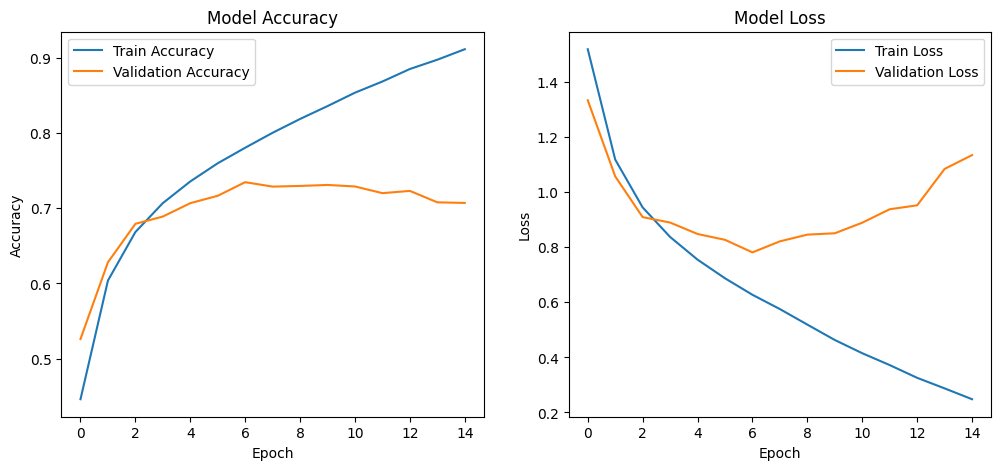

In [35]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1) 
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("Model Accuracy")
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

## 📊 Overfitting Analysis Result

### 🔍 Summary

Model bắt đầu có dấu hiệu **overfitting từ khoảng epoch 5–6**.

---

### 🚨 Observations

#### 1. Train Accuracy >> Validation Accuracy

Model đạt độ chính xác rất cao trên tập train nhưng thấp hơn đáng kể trên tập validation, cho thấy khả năng generalization kém.

---

#### 2. Validation Loss tăng trong khi Train Loss giảm

Trong quá trình training:

* Train Loss tiếp tục giảm
* Validation Loss bắt đầu tăng

Điều này cho thấy model đang học lệch về dữ liệu train và không phản ánh đúng pattern trên dữ liệu mới.

---

### ⚠️ Conclusion

Model đang **overfit**, với các đặc điểm:

* Ghi nhớ dữ liệu train
* Không tổng quát hóa tốt
* Hiệu suất trên validation suy giảm sau epoch 5–6


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


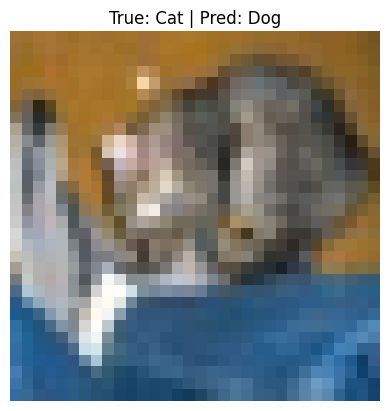

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


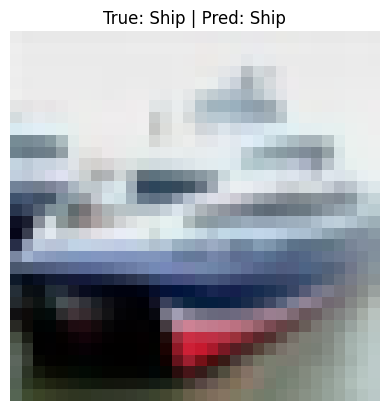

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


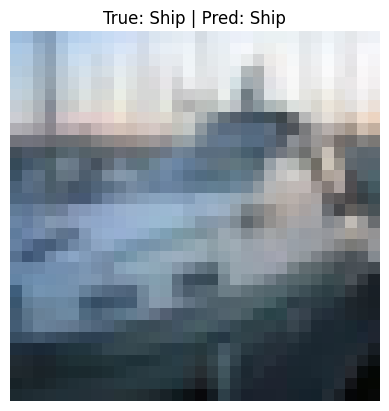

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


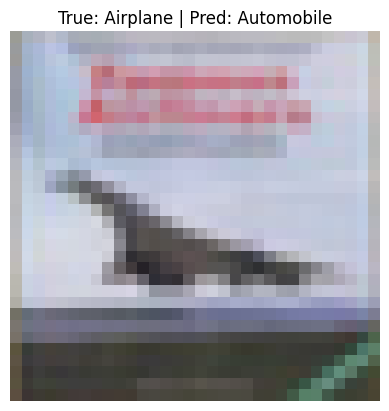

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


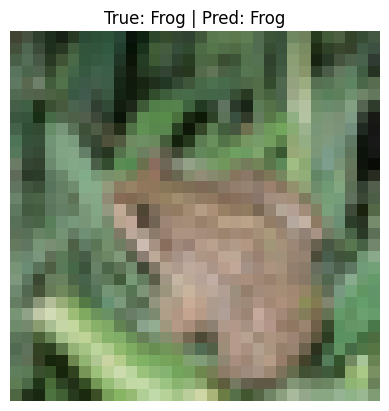

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


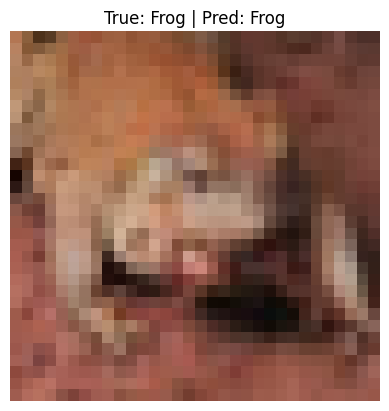

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


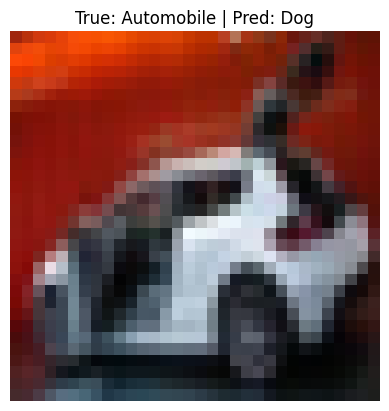

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


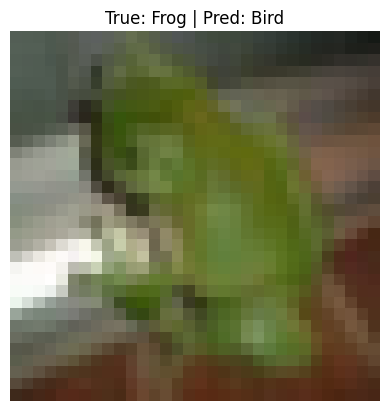

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


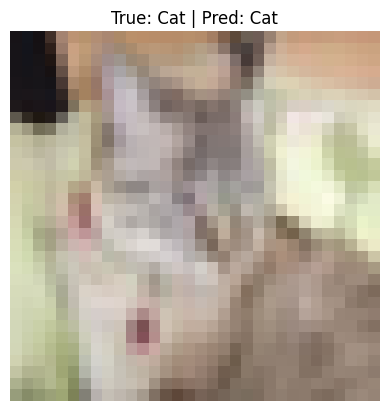

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


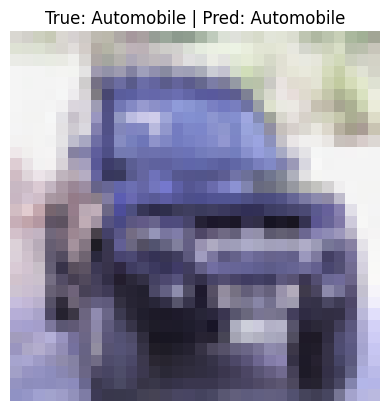

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


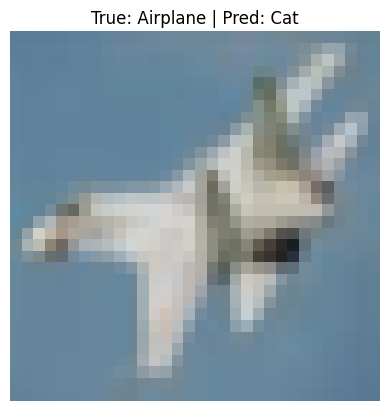

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


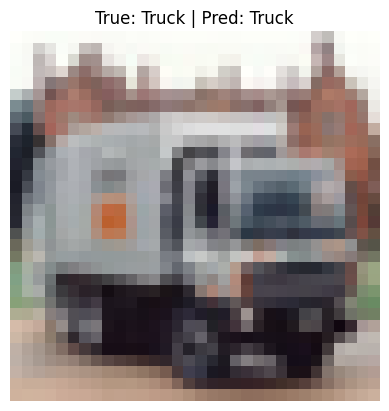

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


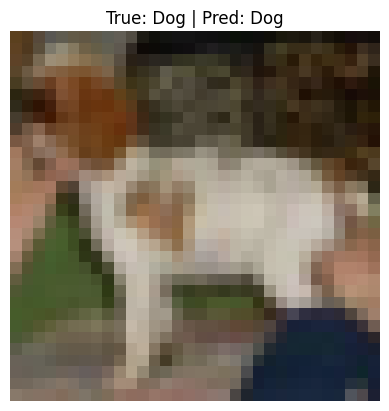

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


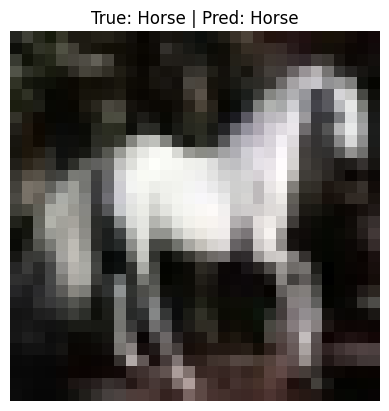

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


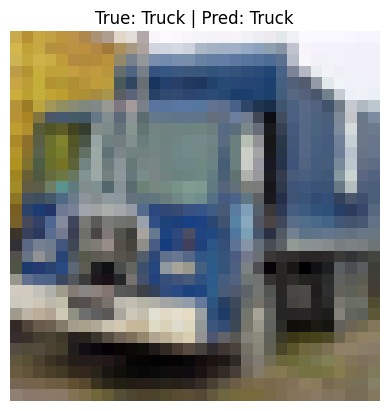

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


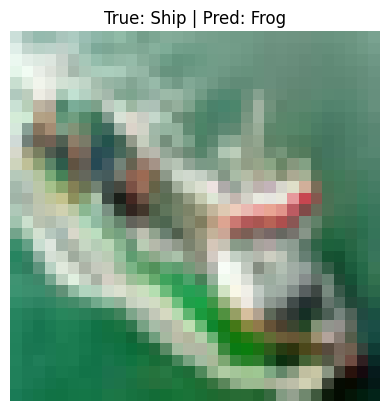

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


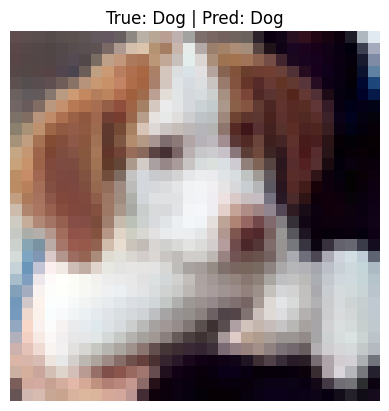

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


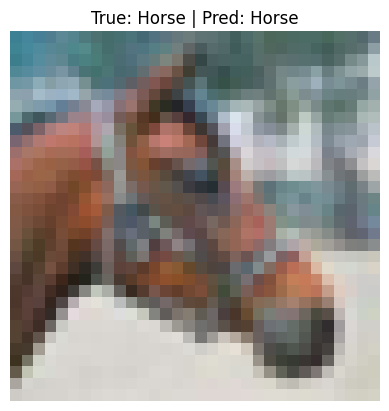

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


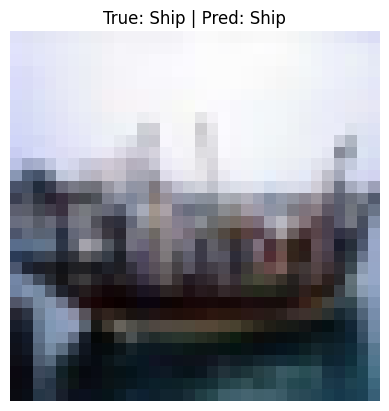

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


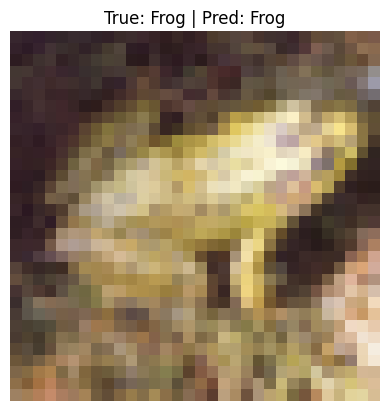

In [37]:
def plot_predictions(index):
    img = x_test[index]
    true_label = class_names[np.argmax(y_test[index])]
    pred_probs = model.predict(np.expand_dims(img, axis=0))
    pred_label = class_names[np.argmax(pred_probs)]
    
    plt.imshow(img)
    plt.title(f"True: {true_label} | Pred: {pred_label}")
    plt.axis('off')
    plt.show()


for i in range(20):
    plot_predictions(i)